In [10]:
import utils
import skimage
import skimage.morphology
import numpy as np
import matplotlib.pyplot as plt

from skimage import metrics

In [14]:
def remove_noise(im: np.ndarray) -> np.ndarray:
    """
        A function that removes noise in the input image.
        args:
            im: np.ndarray of shape (H, W) with boolean values (dtype=bool)
        return:
            (np.ndarray) of shape (H, W). dtype=bool
    """
    ### START YOUR CODE HERE ### (You can change anything inside this block)
    # You can also define other helper functions
    noise_free_image = im.copy()
    closing_matrix = np.ones((20, 20))
    opening_matrix = np.ones((15, 15))
    # dilation_matrix = np.ones((15, 15))
    # erosion_matrix = np.ones((30, 30))
    noise_free_image = skimage.morphology.binary_closing(noise_free_image, closing_matrix)
    noise_free_image = skimage.morphology.binary_erosion(noise_free_image, opening_matrix)
    # noise_free_image = skimage.morphology.binary_dilation(noise_free_image, dilation_matrix)
    # noise_free_image = skimage.morphology.binary_erosion(noise_free_image, erosion_matrix)
    return noise_free_image
    ### END YOUR CODE HERE ### 

Reading image: images/noisy.png
Reading image: images/noisy-filtered-expected.png
Saving image to: image_processed/noisy-filtered.png
Hausdorff Distance: 11.0 (< 10 required)


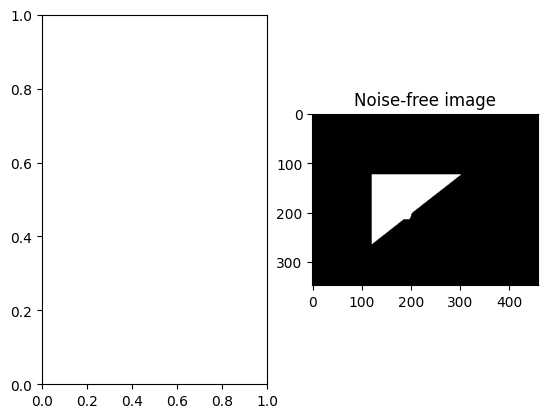

In [ ]:
if __name__ == "__main__":
    # DO NOT CHANGE
    im = utils.read_image("noisy.png")
    expected_result = utils.read_image("noisy-filtered-expected.png")

    binary_image = (im != 0)
    noise_free_image = remove_noise(binary_image)

    assert im.shape == noise_free_image.shape, "Expected image shape ({}) to be same as resulting image shape ({})".format(
            im.shape, noise_free_image.shape)
    assert noise_free_image.dtype == bool, "Expected resulting image dtype to be bool. Was: {}".format(
            noise_free_image.dtype)

    noise_free_image = utils.to_uint8(noise_free_image)
    utils.save_im("noisy-filtered.png", noise_free_image)

    print("Hausdorff Distance:", metrics.hausdorff_distance(expected_result, noise_free_image) , "(< 10 required)")

    fig, ax = plt.subplots(1,1)
    plt.imshow(im, cmap="gray")
    plt.title("Original image")

    fig, ax = plt.subplots(1,1)
    plt.imshow(noise_free_image, cmap="gray")
    plt.title("Noise-free image")

    fig, ax = plt.subplots(1,1)
    plt.imshow(expected_result, cmap="gray")
    plt.title("Expected result")
